# 11. Fine-tuning後のTT-rank trade-off

10でfine-tuningしたrank 16 / 32 / 64の3候補について、TT-rank、parameter数、圧縮率、accuracy recovery、prediction agreement、logits RMSEを比較します。

ここで変えているrankは**TT coreの個数ではなく、隣接core間のbond dimensionの上限**です。3-core TTのcore数は常に3個で、fine-tuning中も各coreのshapeとTT-rankは固定されています。ただし、10のoptimizerはTT coresだけでなく、`fc1`のbias、`fc2`、`fc3`を含むmodelの全parameterを更新しています。TT coresだけを更新するablationはまだ行っていません。

このNotebookではtest setを評価しません。before / afterのPareto frontierをvalidation結果だけで比較し、rank 24 / 48の追加実験が必要かを判断するところで止めます。

## 1. importと入力ファイル

Pareto判定はNotebook内で再実装せず、`src`の`extract_pareto_frontier`を使用します。このAPIは2目的とも小さいほど良い場合を扱うため、accuracyは$1-\mathrm{accuracy}$へ変換して渡します。

In [34]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import ast
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")

from nn_compression.selection import extract_pareto_frontier
from nn_compression.utils import find_project_root


In [35]:
SAVE_RESULTS = True
ROLE_ORDER = ["aggressive", "balanced", "conservative"]
EXPECTED_RANKS = {16, 32, 64}

project_root = find_project_root(Path.cwd())
results_root = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
)
finetuning_path = (
    results_root / "10_pretrained_mlp_fc1_tt_finetuning"
    / "finetuning_comparison.csv"
)
history_path = (
    results_root / "10_pretrained_mlp_fc1_tt_finetuning"
    / "finetuning_history.csv"
)
selection_path = (
    results_root / "09_pretrained_mlp_fc1_tt_tensorization_comparison"
    / "selected_tensorizations.csv"
)
results_dir = results_root / "11_tt_rank_tradeoff_after_finetuning"

for input_path in [finetuning_path, selection_path]:
    if not input_path.is_file():
        raise FileNotFoundError(
            f"必要な入力がありません: {input_path}\n"
            "先にNotebook 09と10を完了し、結果CSVを保存してください。"
        )

print("fine-tuning comparison:", finetuning_path)
print("09 selection:", selection_path)
print("history (optional):", history_path)
print("results target:", results_dir)


fine-tuning comparison: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\10_pretrained_mlp_fc1_tt_finetuning\finetuning_comparison.csv
09 selection: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\09_pretrained_mlp_fc1_tt_tensorization_comparison\selected_tensorizations.csv
history (optional): D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\10_pretrained_mlp_fc1_tt_finetuning\finetuning_history.csv
results target: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\11_tt_rank_tradeoff_after_finetuning


## 2. 09と10の結果を読み込み、実験条件を検証する

10の比較表が3候補を1行ずつ持ち、09で選択したtensorization、modes、rank、parameter数と一致することを確認します。10の結果だけを信用せず、前Notebookとの接続をここで検証します。

In [36]:
df_finetuning = pd.read_csv(finetuning_path)
df_selected_09 = pd.read_csv(selection_path)
df_history = pd.read_csv(history_path) if history_path.is_file() else None

required_finetuning_columns = {
    "selection_role", "tensorization", "out_modes", "in_modes",
    "requested_rank", "actual_ranks",
    "model_parameters_before", "model_parameters_after",
    "model_compression_ratio",
    "validation_accuracy_before", "validation_accuracy_after",
    "accuracy_drop_before", "accuracy_drop_after",
    "accuracy_recovery",
    "prediction_agreement_before", "prediction_agreement_after",
    "logits_rmse_before", "logits_rmse_after",
    "best_epoch", "training_time_sec",
}
required_selection_columns = {
    "selection_role", "tensorization", "out_modes", "in_modes",
    "requested_rank", "actual_ranks", "model_parameters",
}

missing_finetuning = required_finetuning_columns.difference(df_finetuning.columns)
missing_selection = required_selection_columns.difference(df_selected_09.columns)
if missing_finetuning:
    raise ValueError(
        f"10の比較CSVに必要な列がありません: {sorted(missing_finetuning)}"
    )
if missing_selection:
    raise ValueError(
        f"09の選択CSVに必要な列がありません: {sorted(missing_selection)}"
    )

# CSVへ文字列として保存されたtupleを比較可能なtupleへ戻す。
for frame in [df_finetuning, df_selected_09]:
    for column in ["out_modes", "in_modes", "actual_ranks"]:
        frame[column] = frame[column].map(
            lambda value: tuple(ast.literal_eval(value))
            if isinstance(value, str)
            else tuple(value)
        )

assert len(df_finetuning) == 3
assert len(df_selected_09) == 3
assert set(df_finetuning["selection_role"]) == set(ROLE_ORDER)
assert set(df_finetuning["requested_rank"].astype(int)) == EXPECTED_RANKS
assert df_finetuning["selection_role"].is_unique
assert (df_finetuning["tensorization"] == "reversed_sites").all()
assert (
    df_finetuning["model_parameters_before"]
    == df_finetuning["model_parameters_after"]
).all()

comparison_columns = [
    "selection_role", "tensorization", "out_modes", "in_modes",
    "requested_rank", "actual_ranks",
]
df_contract = df_finetuning.merge(
    df_selected_09[comparison_columns + ["model_parameters"]],
    on="selection_role",
    suffixes=("_10", "_09"),
    validate="one_to_one",
)
for column in ["tensorization", "out_modes", "in_modes", "requested_rank", "actual_ranks"]:
    assert (df_contract[f"{column}_10"] == df_contract[f"{column}_09"]).all(), column
assert (
    df_contract["model_parameters_before"]
    == df_contract["model_parameters"]
).all()

for column in [
    "validation_accuracy_before", "validation_accuracy_after",
    "prediction_agreement_before", "prediction_agreement_after",
]:
    assert df_finetuning[column].between(0.0, 1.0).all(), column
for column in ["logits_rmse_before", "logits_rmse_after", "training_time_sec"]:
    assert (df_finetuning[column] >= 0.0).all(), column

# accuracy dropから復元したdense baselineが全行・before/afterで一致することを確認する。
baseline_from_before = (
    df_finetuning["validation_accuracy_before"]
    + df_finetuning["accuracy_drop_before"]
)
baseline_from_after = (
    df_finetuning["validation_accuracy_after"]
    + df_finetuning["accuracy_drop_after"]
)
assert torch.allclose(
    torch.tensor(baseline_from_before.to_numpy()),
    torch.tensor(baseline_from_after.to_numpy()),
    rtol=1e-6, atol=1e-6,
)
assert float(baseline_from_before.max() - baseline_from_before.min()) <= 1e-6
dense_baseline_validation_accuracy = float(baseline_from_before.iloc[0])

df_finetuning["selection_role"] = pd.Categorical(
    df_finetuning["selection_role"], categories=ROLE_ORDER, ordered=True
)
df_finetuning = df_finetuning.sort_values("requested_rank").reset_index(drop=True)

print(f"dense baseline validation accuracy: {dense_baseline_validation_accuracy:.6f}")
display(df_finetuning[[
    "selection_role", "tensorization", "requested_rank", "actual_ranks",
    "model_parameters_before", "model_compression_ratio",
    "validation_accuracy_before", "validation_accuracy_after",
    "accuracy_recovery",
    "prediction_agreement_before", "prediction_agreement_after",
    "logits_rmse_before", "logits_rmse_after",
    "best_epoch", "training_time_sec",
]].round(6))


dense baseline validation accuracy: 0.888400


,selection_role,tensorization,requested_rank,actual_ranks,model_parameters_before,model_compression_ratio,validation_accuracy_before,validation_accuracy_after,accuracy_recovery,prediction_agreement_before,prediction_agreement_after,logits_rmse_before,logits_rmse_after,best_epoch,training_time_sec
0,aggressive,reversed_sites,16,"(1, 16, 16, 1)",153386,3.493265,0.5116,0.889,0.3774,0.5276,0.9314,7.933703,3.666437,5,64.865658
1,balanced,reversed_sites,32,"(1, 32, 32, 1)",205130,2.612090,0.7980,0.885,0.0870,0.8460,0.9298,4.451787,7.104990,5,94.706784
2,conservative,reversed_sites,64,"(1, 64, 64, 1)",406922,1.316758,0.8872,0.885,-0.0022,0.9922,0.9208,0.179470,11.700915,6,188.513939


## 3. TODO 1：before / afterをlong形式に整理する

### このセルで確認すること

同じrankのbeforeとafterを同一の列名で扱えるように、各候補を2行へ変換します。`stage`列は`before`または`after`とし、accuracy、agreement、logits RMSEを対応する列へ入れます。

parameter数とcompression ratioはfine-tuningで変化しません。期待する結果は、3 ranksと2 stagesの組合せで6行です。accuracy recoveryはafter minus beforeなので、元のwide形式の値とも一致することを検証してください。

In [37]:
# TODO 1: df_finetuningからdf_rank_stageを作る。
#
# 目的: wide形式（候補1行に before/after 列が横並び）を
#       long形式（候補×stageで2行、指標列名は共通）へ変換する。
#
# 使用する列:
#   共通: selection_role, tensorization, requested_rank, actual_ranks,
#         model_parameters_before, model_compression_ratio
#   before/after: validation_accuracy_*, prediction_agreement_*, logits_rmse_*

# fine-tuning前後で変わらない列（候補の識別子と圧縮量）
common_columns = [
    "selection_role",
    "tensorization",
    "requested_rank",
    "actual_ranks",
    "model_parameters_before",
    "model_compression_ratio",
]
frames = []

# stageごとに「その段階の指標列だけ」を抜き出し、列名を揃えて積む
for stage in ["before", "after"]:
    stage_columns = [
        f"validation_accuracy_{stage}",
        f"prediction_agreement_{stage}",
        f"logits_rmse_{stage}",
    ]

    frame = df_finetuning[common_columns + stage_columns].copy()
    # 段階名付き列 → 共通列名へ。parameter列もPareto用に model_parameters へ統一
    frame = frame.rename(
        columns={
            "model_parameters_before": "model_parameters",
            f"validation_accuracy_{stage}": "validation_accuracy",
            f"prediction_agreement_{stage}": "prediction_agreement",
            f"logits_rmse_{stage}": "logits_rmse",
        }
    )
    frame["stage"] = stage  # この3行が before か after かを明示
    frames.append(frame)

# before 3行 + after 3行 = 6行の long DataFrame
df_rank_stage = (
    pd.concat(frames, ignore_index=True)
    .assign(
        # 並びと凡例を固定するため Categorical にする
        stage=lambda df: pd.Categorical(
            df["stage"],
            categories=["before", "after"],
            ordered=True,
        ),
        selection_role=lambda df: pd.Categorical(
            df["selection_role"],
            categories=ROLE_ORDER,
            ordered=True,
        ),
    )
    .sort_values(["requested_rank", "stage"])
    .reset_index(drop=True)
)

# 構造チェック: 3 ranks × 2 stages
assert len(df_rank_stage) == 6
assert set(df_rank_stage["stage"]) == {"before", "after"}
assert (
    df_rank_stage.groupby("requested_rank", observed=True).size() == 2
).all()

# 意味チェック: longから計算した recovery が、元の wide 列と一致するか
recovery_from_long = (
    df_rank_stage.pivot(
        index="requested_rank",
        columns="stage",
        values="validation_accuracy",
    )
    .assign(accuracy_recovery=lambda df: df["after"] - df["before"])
)
recovery_from_wide = (
    df_finetuning.set_index("requested_rank")["accuracy_recovery"]
    .astype(float)
)
assert recovery_from_long["accuracy_recovery"].sub(recovery_from_wide).abs().max() < 1e-12

display(df_rank_stage[[
    "selection_role",
    "tensorization",
    "requested_rank",
    "actual_ranks",
    "stage",
    "model_parameters",
    "model_compression_ratio",
    "validation_accuracy",
    "prediction_agreement",
    "logits_rmse",
]].round(6))


,selection_role,tensorization,requested_rank,actual_ranks,stage,model_parameters,model_compression_ratio,validation_accuracy,prediction_agreement,logits_rmse
0,aggressive,reversed_sites,16,"(1, 16, 16, 1)",before,153386,3.493265,0.5116,0.5276,7.933703
1,aggressive,reversed_sites,16,"(1, 16, 16, 1)",after,153386,3.493265,0.8890,0.9314,3.666437
2,balanced,reversed_sites,32,"(1, 32, 32, 1)",before,205130,2.612090,0.7980,0.8460,4.451787
3,balanced,reversed_sites,32,"(1, 32, 32, 1)",after,205130,2.612090,0.8850,0.9298,7.104990
4,conservative,reversed_sites,64,"(1, 64, 64, 1)",before,406922,1.316758,0.8872,0.9922,0.179470
5,conservative,reversed_sites,64,"(1, 64, 64, 1)",after,406922,1.316758,0.8850,0.9208,11.700915


## 4. TODO 2：before / afterのPareto frontierを別々に求める

Paretoの目的は、model parameter数の最小化とvalidation accuracyの最大化です。既存APIへ渡すため、stageごとに次を作ります。

$$
\mathrm{validation\ error}=1-\mathrm{validation\ accuracy}
$$

`extract_pareto_frontier(frame, "model_parameters", "validation_error")`をbeforeとafterへ**別々に**適用してください。beforeとafterを同じ集合としてPareto判定すると、fine-tuningの効果とrankのtrade-offが混ざるため不適切です。

このNotebookでは自動選択ルールや最終rankを確定しません。frontierに残った点と、fine-tuningによってfrontierがどう変わったかを観察します。

In [38]:
# TODO 2: df_rank_stageをstageで分割し、既存APIでPareto frontierを求める。
#
# 1. beforeだけのDataFrameにvalidation_errorを追加する。
# [修正] SettingWithCopyWarning回避のため .copy() を付与
df_before = df_rank_stage.loc[df_rank_stage["stage"] == "before"].copy()
df_before["validation_error"] = 1 - df_before["validation_accuracy"]
# 2. extract_pareto_frontierを呼び、df_pareto_beforeを作る。
df_pareto_before = extract_pareto_frontier(df_before,"model_parameters", "validation_error")
# 3. afterについても独立に処理し、df_pareto_afterを作る。
# [修正] SettingWithCopyWarning回避のため .copy() を付与
df_after = df_rank_stage.loc[df_rank_stage["stage"] == "after"].copy()
df_after["validation_error"] = 1 - df_after["validation_accuracy"]
df_pareto_after = extract_pareto_frontier(
    df_after, "model_parameters", "validation_error"
)

# 4. 両方をmodel_parameters昇順で表示する。
df_pareto_before = (
    df_pareto_before
    .sort_values("model_parameters")
    .reset_index(drop=True)
)

df_pareto_after = (
    df_pareto_after
    .sort_values("model_parameters")
    .reset_index(drop=True)
)

display(df_pareto_before)
display(df_pareto_after)
#
# 期待結果: 各行は、より少ないparameter数か、より高いaccuracyの少なくとも
# 一方を改善しなければ置き換えられない候補である。validation_errorは表示・保存前に
# 残してもよいが、accuracyとの意味の違いを明示する。


,selection_role,tensorization,requested_rank,actual_ranks,model_parameters,model_compression_ratio,validation_accuracy,prediction_agreement,logits_rmse,stage,validation_error
0,aggressive,reversed_sites,16,"(1, 16, 16, 1)",153386,3.493265,0.5116,0.5276,7.933703,before,0.4884
1,balanced,reversed_sites,32,"(1, 32, 32, 1)",205130,2.612090,0.7980,0.8460,4.451787,before,0.2020
2,conservative,reversed_sites,64,"(1, 64, 64, 1)",406922,1.316758,0.8872,0.9922,0.179470,before,0.1128


,selection_role,tensorization,requested_rank,actual_ranks,model_parameters,model_compression_ratio,validation_accuracy,prediction_agreement,logits_rmse,stage,validation_error
0,aggressive,reversed_sites,16,"(1, 16, 16, 1)",153386,3.493265,0.889,0.9314,3.666437,after,0.111


## 5. TODO 3：TT-rank trade-offを可視化する

次の5つを可視化します。

1. requested rank対before / after validation accuracyとdense baseline
2. requested rank対accuracy recovery
3. model compression ratio対after accuracyとafter Pareto frontier
4. requested rank対before / after prediction agreement
5. requested rank対before / after logits RMSE

accuracyは正解ラベルとの一致、agreementはdense baselineの予測との一致で比較対象が異なります。この2指標を同じsubplotへ重ねないでください。accuracyとagreementの縦軸は0〜1にします。rank軸は16 / 32 / 64が明確に読めるようにしてください。

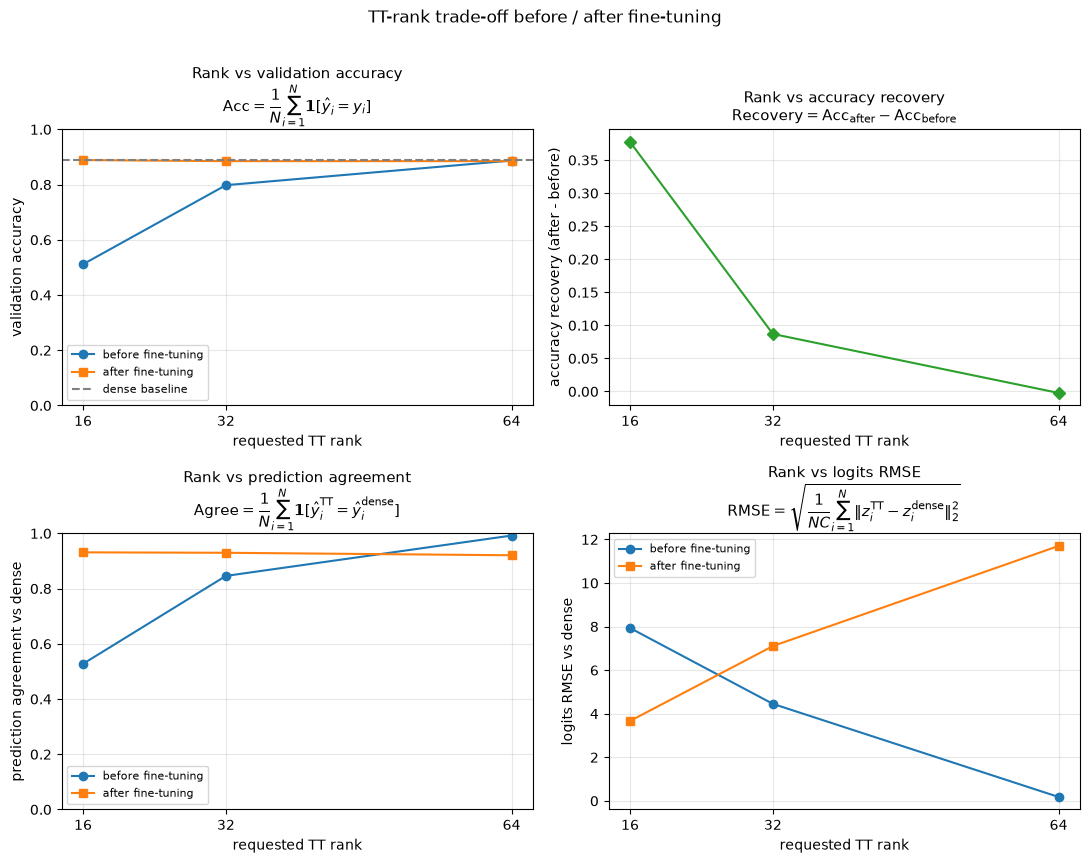

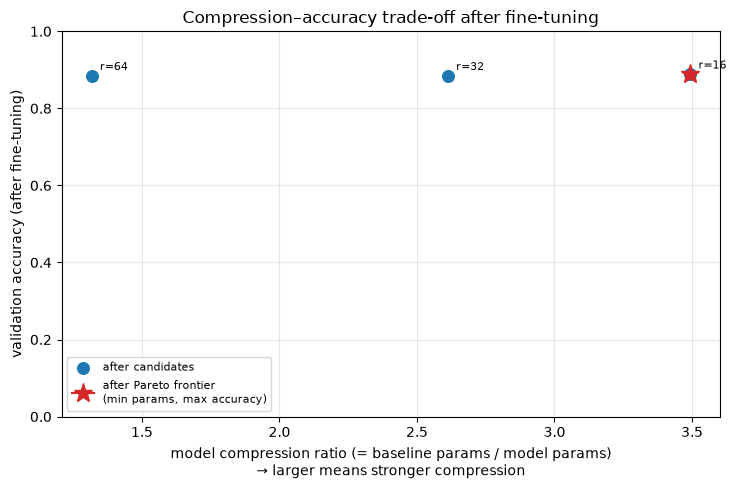

In [39]:
# TODO 3: matplotlibでtrade-off Figureを作る。
#
# 推奨変数名:
#   fig_rank_tradeoff: accuracy / recovery / agreement / logits RMSEの4 axes
#   fig_compression_pareto: compression ratio vs after accuracy
#
# accuracyのaxisだけにdense_baseline_validation_accuracyの水平破線を描く。
# compression比は大きいほど圧縮が強いので、軸方向とParetoの意味をラベルで明示する。
# after Pareto点は通常候補と区別できるmarkerまたは線で示す。

ranks = sorted(EXPECTED_RANKS)
df_before_plot = (
    df_rank_stage.loc[df_rank_stage["stage"] == "before"]
    .sort_values("requested_rank")
)
df_after_plot = (
    df_rank_stage.loc[df_rank_stage["stage"] == "after"]
    .sort_values("requested_rank")
)
df_recovery_plot = df_finetuning.sort_values("requested_rank")

# --- Figure 1: rank trade-off（4 panels） ---
fig_rank_tradeoff, axes = plt.subplots(2, 2, figsize=(11, 8.5))
ax_acc, ax_rec, ax_agr, ax_rmse = axes.ravel()

# 縦軸の定義式は title の2行目へ置く（axes内の線と重ならない）
def set_title_with_formula(ax, title, formula):
    ax.set_title(f"{title}\n{formula}", fontsize=11)

# 1) requested rank vs validation accuracy（before / after）+ dense baseline
ax_acc.plot(
    df_before_plot["requested_rank"],
    df_before_plot["validation_accuracy"],
    marker="o",
    label="before fine-tuning",
)
ax_acc.plot(
    df_after_plot["requested_rank"],
    df_after_plot["validation_accuracy"],
    marker="s",
    label="after fine-tuning",
)
ax_acc.axhline(
    dense_baseline_validation_accuracy,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="dense baseline",
)
ax_acc.set_xticks(ranks)
ax_acc.set_ylim(0.0, 1.0)
ax_acc.set_xlabel("requested TT rank")
ax_acc.set_ylabel("validation accuracy")
set_title_with_formula(
    ax_acc,
    "Rank vs validation accuracy",
    r"$\mathrm{Acc}=\dfrac{1}{N}\sum_{i=1}^{N}"
    r"\mathbf{1}[\hat{y}_i=y_i]$",
)
ax_acc.grid(True, alpha=0.3)
ax_acc.legend(fontsize=8)

# 2) requested rank vs accuracy recovery
ax_rec.plot(
    df_recovery_plot["requested_rank"],
    df_recovery_plot["accuracy_recovery"],
    marker="D",
    color="C2",
)
ax_rec.set_xticks(ranks)
ax_rec.set_xlabel("requested TT rank")
ax_rec.set_ylabel("accuracy recovery (after - before)")
set_title_with_formula(
    ax_rec,
    "Rank vs accuracy recovery",
    r"$\mathrm{Recovery}"
    r"=\mathrm{Acc}_{\mathrm{after}}"
    r"-\mathrm{Acc}_{\mathrm{before}}$",
)
ax_rec.grid(True, alpha=0.3)

# 3) requested rank vs prediction agreement（before / after）
ax_agr.plot(
    df_before_plot["requested_rank"],
    df_before_plot["prediction_agreement"],
    marker="o",
    label="before fine-tuning",
)
ax_agr.plot(
    df_after_plot["requested_rank"],
    df_after_plot["prediction_agreement"],
    marker="s",
    label="after fine-tuning",
)
ax_agr.set_xticks(ranks)
ax_agr.set_ylim(0.0, 1.0)
ax_agr.set_xlabel("requested TT rank")
ax_agr.set_ylabel("prediction agreement vs dense")
set_title_with_formula(
    ax_agr,
    "Rank vs prediction agreement",
    r"$\mathrm{Agree}=\dfrac{1}{N}\sum_{i=1}^{N}"
    r"\mathbf{1}[\hat{y}^{\mathrm{TT}}_i"
    r"=\hat{y}^{\mathrm{dense}}_i]$",
)
ax_agr.grid(True, alpha=0.3)
ax_agr.legend(fontsize=8)

# 4) requested rank vs logits RMSE（before / after）
ax_rmse.plot(
    df_before_plot["requested_rank"],
    df_before_plot["logits_rmse"],
    marker="o",
    label="before fine-tuning",
)
ax_rmse.plot(
    df_after_plot["requested_rank"],
    df_after_plot["logits_rmse"],
    marker="s",
    label="after fine-tuning",
)
ax_rmse.set_xticks(ranks)
ax_rmse.set_xlabel("requested TT rank")
ax_rmse.set_ylabel("logits RMSE vs dense")
set_title_with_formula(
    ax_rmse,
    "Rank vs logits RMSE",
    r"$\mathrm{RMSE}=\sqrt{\dfrac{1}{NC}"
    r"\sum_{i=1}^{N}\|z^{\mathrm{TT}}_i"
    r"-z^{\mathrm{dense}}_i\|_2^2}$",
)
ax_rmse.grid(True, alpha=0.3)
ax_rmse.legend(fontsize=8)

fig_rank_tradeoff.suptitle(
    "TT-rank trade-off before / after fine-tuning",
    y=1.01,
)
fig_rank_tradeoff.tight_layout()
plt.show()

# --- Figure 2: compression ratio vs after accuracy + after Pareto ---
fig_compression_pareto, ax_cp = plt.subplots(figsize=(7.5, 5.0))

ax_cp.scatter(
    df_after_plot["model_compression_ratio"],
    df_after_plot["validation_accuracy"],
    s=70,
    zorder=3,
    label="after candidates",
)
for _, row in df_after_plot.iterrows():
    ax_cp.annotate(
        f"r={int(row.requested_rank)}",
        (row.model_compression_ratio, row.validation_accuracy),
        textcoords="offset points",
        xytext=(6, 4),
        fontsize=8,
    )

df_pareto_after_plot = df_pareto_after.sort_values("model_parameters")
ax_cp.plot(
    df_pareto_after_plot["model_compression_ratio"],
    df_pareto_after_plot["validation_accuracy"],
    color="C3",
    marker="*",
    markersize=14,
    linestyle="-",
    linewidth=1.5,
    zorder=4,
    label="after Pareto frontier\n(min params, max accuracy)",
)

ax_cp.set_ylim(0.0, 1.0)
ax_cp.set_xlabel(
    "model compression ratio (= baseline params / model params)\n"
    "→ larger means stronger compression"
)
ax_cp.set_ylabel("validation accuracy (after fine-tuning)")
ax_cp.set_title("Compression–accuracy trade-off after fine-tuning")
ax_cp.grid(True, alpha=0.3)
ax_cp.legend(fontsize=8, loc="lower left")
fig_compression_pareto.tight_layout()
plt.show()


## 6. TODO 4：rank 12 / 24 / 48を追加すべきか判断する

追加rankは常に学習するのではなく、既存区間に未解像のtrade-offが残る場合、または現在の最小rankより強い圧縮を調べる余地がある場合だけ要求します。

- 現在の最小候補rank 16がfine-tuning後に十分なaccuracy recoveryを示し、さらに強い圧縮の余地を調べたいならrank 12
- rank 16から32でaccuracy、agreement、logits RMSEが大きく変化し、圧縮率との中間点が必要ならrank 24
- rank 32から64で同様の変化が残り、dense baselineへ近づく途中を確認したいならrank 48
- 既存3点だけでfrontierと実用上の選択が明確なら追加なし

何を「大きな変化」とするかは、結果を見る前に閾値を決めてください。accuracyだけで自動決定せず、agreement、logits RMSE、compression ratioも併記します。このNotebookでは追加fine-tuningを実行せず、必要なrankと理由をCSVへ渡すだけです。

In [40]:
# TODO 4: 既存rank間の変化量と低rank側の探索余地から、追加実験の要否を判断する。
#
# 最初にaccuracy差などの判定閾値を、結果を見て都合よく変えない形で定義する。
# rank 16で性能が十分回復し、より強い圧縮側を調べる価値があればrequested_rank=12を候補とする。
# 16-32区間が条件を満たす場合はrequested_rank=24、32-64区間なら48を候補とする。
# df_additional_rank_requestsには少なくとも次を入れる:
#   requested_rank, between_rank_low, between_rank_high, reason
# rank 12は既存候補間の中点ではないため、between_rank_lowはpd.NA、between_rank_highは16とする。
# 全候補のafter結果：16・32・64

# [修正2] 追加不要の場合も、所定列を持つ空DataFrameを最初に作る
request_columns = [
    "requested_rank",
    "between_rank_low",
    "between_rank_high",
    "reason",
]
df_additional_rank_requests = pd.DataFrame(columns=request_columns)

df_after = df_rank_stage.loc[
    df_rank_stage["stage"] == "after"
].copy()

accuracy_by_rank = df_after.set_index("requested_rank")[
    "validation_accuracy"
]
# [修正1] 24/48判定用に agreement / logits RMSE も index 化する
agreement_by_rank = df_after.set_index("requested_rank")[
    "prediction_agreement"
]
logits_rmse_by_rank = df_after.set_index("requested_rank")[
    "logits_rmse"
]
display(accuracy_by_rank)

# TODO 2で作ったPareto結果から、探索方針を決める
only_rank_16_on_frontier = (
    set(df_pareto_after["requested_rank"]) == {16}
)

explore_higher_ranks = not only_rank_16_on_frontier

# [修正1] 結果を見る前に固定する隣接rank間の閾値
ACCURACY_TOLERANCE = 0.001
ACCURACY_GAP_THRESHOLD = 0.02
AGREEMENT_GAP_THRESHOLD = 0.02
LOGITS_RMSE_GAP_THRESHOLD = 0.5

rank_16_is_good_enough = (
    accuracy_by_rank.loc[16] >= dense_baseline_validation_accuracy - ACCURACY_TOLERANCE
)

# [修正1] accuracy / agreement / logits RMSE のいずれかが大きければ中点を要求
def large_change(rank_low, rank_high):
    return (
        abs(accuracy_by_rank.loc[rank_high] - accuracy_by_rank.loc[rank_low])
        >= ACCURACY_GAP_THRESHOLD
        or abs(agreement_by_rank.loc[rank_high] - agreement_by_rank.loc[rank_low])
        >= AGREEMENT_GAP_THRESHOLD
        or abs(logits_rmse_by_rank.loc[rank_high] - logits_rmse_by_rank.loc[rank_low])
        >= LOGITS_RMSE_GAP_THRESHOLD
    )

requests = []
if rank_16_is_good_enough:
    requests.append({
        "requested_rank": 12,
        "between_rank_low": pd.NA,
        "between_rank_high": 16,
        "reason": (
            "rank 16のfine-tuning後accuracyがdenseとの差の許容範囲内なので、"
            "さらに低rankでも精度を維持できるか確認する"
        ),
    })

# [修正1] 未使用だった explore_higher_ranks で 24/48 を判定
if explore_higher_ranks:
    if large_change(16, 32):
        requests.append({
            "requested_rank": 24,
            "between_rank_low": 16,
            "between_rank_high": 32,
            "reason": (
                "rank 16-32でaccuracy / agreement / logits RMSEの"
                "少なくとも1つが大きく変化したため中間点を確認する"
            ),
        })
    if large_change(32, 64):
        requests.append({
            "requested_rank": 48,
            "between_rank_low": 32,
            "between_rank_high": 64,
            "reason": (
                "rank 32-64でaccuracy / agreement / logits RMSEの"
                "少なくとも1つが大きく変化したため中間点を確認する"
            ),
        })

df_additional_rank_requests = pd.DataFrame(
    requests,
    columns=request_columns,
)
display(df_additional_rank_requests)


requested_rank
16    0.889
32    0.885
64    0.885
Name: validation_accuracy, dtype: float64

,requested_rank,between_rank_low,between_rank_high,reason
0,12,<NA>,16,rank 16のfine-tuning後accuracyがdenseとの差の許容範囲内なので...


## 7. TODO 5：表とFigureを保存する

分析結果だけを保存します。11ではmodel checkpointを保存しません。tuple列をCSVへ出す場合は文字列へ変換し、入力DataFrame自体を破壊しないcopyを使ってください。

In [41]:
# TODO 5: SAVE_RESULTS=Trueのときresults_dirを作り、以下を保存する。
#
# rank_tradeoff_after_finetuning.csv
# pareto_before_finetuning.csv
# pareto_after_finetuning.csv
# additional_rank_requests.csv  # 候補がある場合だけ
# tt_rank_tradeoff_after_finetuning.png
# tt_compression_accuracy_pareto_after_finetuning.png
#
# 保存後は、作成した各pathがis_file()であることを確認する。

if SAVE_RESULTS:
    results_dir.mkdir(parents=True, exist_ok=True)

    def prepare_csv_frame(frame):
        """in-memoryのDataFrameは壊さず、CSV用copyだけtuple列を文字列化する。"""
        out = frame.copy()
        for column in out.columns:
            if out[column].map(lambda value: isinstance(value, tuple)).any():
                out[column] = out[column].map(str)
        return out

    path_rank_tradeoff = results_dir / "rank_tradeoff_after_finetuning.csv"
    path_pareto_before = results_dir / "pareto_before_finetuning.csv"
    path_pareto_after = results_dir / "pareto_after_finetuning.csv"
    path_additional = results_dir / "additional_rank_requests.csv"
    path_fig_rank = results_dir / "tt_rank_tradeoff_after_finetuning.png"
    path_fig_pareto = (
        results_dir / "tt_compression_accuracy_pareto_after_finetuning.png"
    )

    prepare_csv_frame(df_rank_stage).to_csv(path_rank_tradeoff, index=False)
    prepare_csv_frame(df_pareto_before).to_csv(path_pareto_before, index=False)
    prepare_csv_frame(df_pareto_after).to_csv(path_pareto_after, index=False)

    saved_paths = [
        path_rank_tradeoff,
        path_pareto_before,
        path_pareto_after,
        path_fig_rank,
        path_fig_pareto,
    ]

    # 追加rank候補があるときだけCSVを残す（空表は保存しない）
    if len(df_additional_rank_requests) > 0:
        prepare_csv_frame(df_additional_rank_requests).to_csv(
            path_additional,
            index=False,
        )
        saved_paths.append(path_additional)
    elif path_additional.is_file():
        # 前回実行の残骸が残らないようにする
        path_additional.unlink()

    fig_rank_tradeoff.savefig(path_fig_rank, dpi=150, bbox_inches="tight")
    fig_compression_pareto.savefig(
        path_fig_pareto,
        dpi=150,
        bbox_inches="tight",
    )

    for path_item in saved_paths:
        assert path_item.is_file(), path_item

    print("saved to:", results_dir)
    for path_item in saved_paths:
        print(" -", path_item.name)
else:
    print("SAVE_RESULTS=False: 結果は保存していません。")


saved to: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\11_tt_rank_tradeoff_after_finetuning
 - rank_tradeoff_after_finetuning.csv
 - pareto_before_finetuning.csv
 - pareto_after_finetuning.csv
 - tt_rank_tradeoff_after_finetuning.png
 - tt_compression_accuracy_pareto_after_finetuning.png
 - additional_rank_requests.csv


## 8. 考察の観点

実装後は、次をNotebook考察用の別チャットで検討します。

- 低rankほどaccuracy recoveryが大きいか、それでもdense baselineとの差が残るか
- rank増加とfine-tuningのどちらがaccuracy改善へ大きく寄与したか
- agreementが高くてもaccuracyと同じ意味ではないこと
- logits RMSEの改善とaccuracy回復が同じ傾向か
- fine-tuningによってbefore / afterのPareto frontierが変わったか
- rank 24 / 48の追加実験に、計算コストに見合う情報価値があるか

ここでは最終rankを自動確定しません。追加実験が不要と判断できた場合、12でvalidation結果に基づいて最終rankを固定し、その後にtest setを1回だけ評価します。Fashion-MNIST MLPを完了した後、CNNは別ディレクトリのTT-Conv系列として扱います。